# Decision Trees Workshop
## Predicting Hotel Cancellations

We're using the **Hotel Booking Demand** dataset: 119,390 bookings at two hotels in Portugal (a City Hotel in Lisbon and a Resort Hotel in the Algarve), for arrivals between July 2015 and August 2017. Our goal is to **predict whether a booking will be canceled**.

The target is `is_canceled` (1 = canceled, 0 = not). It's binary, so this is a **classification** problem.

---

### Plan

1. **Explore:** shape, descriptive stats, target balance, quick charts
2. **Clean:** drop the columns we wouldn't actually have, fill missing values
3. **Encode:** one-hot the text columns
4. **Split:** 80% train / 20% test, stratified
5. **Fit:** a small tree, then a loop over `max_depth` to see how depth changes the model
6. **Evaluate:** accuracy vs. a baseline, the confusion matrix, and what the tree leans on
7. Wrap-up + challenges

---

**How this notebook works**

Cells are marked with these emojis.
- ✏️: Write these. The instructions above each one tell you exactly what to type and what to name things so that later cells work.
- 💬: Stop and think, or talk to the people next to you. Answers can go in the markdown cell below.
- 👀: Observe. These are notes to keep in mind.

Make sure to run each cell as you go (in order), or something later on might not work!

---

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

pd.set_option('display.max_columns', None)
DATA_URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv"

## 1. Explore

Each row is **one booking**. 

| Group | Column | Meaning |
|---|---|---|
| **Target** | `is_canceled` | **1 = the booking was canceled, 0 = it wasn't. This is what we predict.** |
| Hotel | `hotel` | `City Hotel` or `Resort Hotel` |
| Timing | `lead_time` | Days between making the booking and the arrival date |
| | `arrival_date_year`, `arrival_date_month`, `arrival_date_week_number`, `arrival_date_day_of_month` | When the guest is supposed to arrive |
| The stay | `stays_in_weekend_nights`, `stays_in_week_nights` | Number of nights booked |
| | `meal` | Meal plan (`BB` = bed & breakfast, `HB` = half board, ...) |
| | `reserved_room_type` | Room type that was booked (coded A, B, C, ...) |
| Who's coming | `adults`, `children`, `babies` | Number of guests |
| | `customer_type` | `Transient`, `Contract`, `Group`, ... |
| | `country` | Guest's country |
| How it was booked | `market_segment`, `distribution_channel` | e.g. `Online TA` = online travel agent |
| | `agent`, `company` | **ID numbers** of the travel agency / company that made the booking |
| Guest history | `is_repeated_guest` | 1 = has stayed before |
| | `previous_cancellations`, `previous_bookings_not_canceled` | This guest's past record |
| Money and requests | `adr` | Average daily rate (price per night, €) |
| | `deposit_type` | `No Deposit`, `Non Refund`, or `Refundable` |
| | `required_car_parking_spaces`, `total_of_special_requests` | What the guest asked for |
| After the fact | `reservation_status`, `reservation_status_date` | Final status (`Canceled`, `No-Show`, `Check-Out`) and when it was set |
| | `assigned_room_type`, `booking_changes`, `days_in_waiting_list` | Room actually given, number of changes, days waiting for confirmation |

✏️ **Load the data**

Write these three lines in the cell below:
1. `df = pd.read_csv(DATA_URL)` to load the data into a DataFrame called `df`
2. `print(df.shape)` to see how many rows and columns there are
3. `df.head()` to look at the first 5 rows

In [2]:
df = pd.read_csv(DATA_URL)
print(df.shape)
df.head()

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### Descriptive statistics

✏️ Write `df.describe()` to get count, mean, std, min, quartiles, and max for every numeric column.

In [3]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


👀 **Observe**
- The mean of a 0/1 column is the **share of 1s**. So the mean of `is_canceled` is the cancellation rate: about **37%**.
- `agent` and `company` show up with means and quartiles, but they're **ID numbers**. Agent 240 isn't "more" than agent 9, so those stats mean nothing. (Same problem as `Store` in the linear regression workshop.)
- A few strange values (a negative price, a €5,400 night, 55 adults) are probably typos or group bookings. Trees handle outliers pretty well: a split like "is `adr` ≤ 150?" doesn't care whether the biggest value is 500 or 5,400.

`describe()` only covers numbers by default. For text columns, you get the count, the number of unique values, the most common value (`top`), and how often it appears (`freq`).

✏️ Write `df[["hotel", "meal", "market_segment", "deposit_type", "customer_type"]].describe()`

In [4]:
df[["hotel", "meal", "market_segment", "deposit_type", "customer_type"]].describe()

,hotel,meal,market_segment,deposit_type,customer_type
count,119390,119390,119390,119390,119390
unique,2,5,8,3,4
top,City Hotel,BB,Online TA,No Deposit,Transient
freq,79330,92310,56477,104641,89613


✏️ **See every category**

`describe()` tells us *how many* unique values each column has, but not what they are. Write a loop that prints them all:

1. Make a list of the text columns:
   `text_cols = ["hotel", "meal", "market_segment", "deposit_type", "customer_type"]`
2. Start the loop: `for col in text_cols:`
3. **Inside the loop** (indented), print the counts for that column:
   `print(df[col].value_counts())`
4. Still inside the loop, add `print()` so there's a blank line between columns.

In [6]:
text_cols = ["hotel", "meal", "market_segment", "deposit_type", "customer_type"]

for col in text_cols:
    print(df[col].value_counts())
    print()

hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64

market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64

deposit_type
No Deposit    104641
Non Refund     14587
Refundable       162
Name: count, dtype: int64

customer_type
Transient          89613
Transient-Party    25124
Contract            4076
Group                577
Name: count, dtype: int64



💬 **What looks unfamiliar?**

A lot of these categories are **hotel-industry jargon**. Go through the lists and pick out any values you don't recognize. What do you *guess* they mean?

Some to start with: `HB`, `SC`, `Offline TA/TO`, `Complementary`, `Aviation`, `Transient-Party`.

Then think about it:
- Where would you look to find out what these mean?
- Why does it matter to know *before* you model? (Imagine explaining your tree to the hotel manager: "bookings in segment X cancel more." Can you explain X?)

*Your answer:*

👀 **Observe: what the codes mean**

When you hit unfamiliar values, check the **data dictionary** first. For this dataset, that's the TidyTuesday readme. In real projects, the data dictionary might be missing, vague, or full of internal jargon. When that happens, ask someone who knows the business.

| Column | Value | Meaning |
|---|---|---|
| `meal` | `BB` | Bed & breakfast |
| | `HB` | Half board: breakfast + one other meal (usually dinner) |
| | `FB` | Full board: breakfast, lunch, and dinner |
| | `SC` | Self catering: no meal package |
| | `Undefined` | No meal package. The documentation treats it the same as `SC`, so it's the **same thing under two labels** |
| `market_segment` | `Online TA` | Online travel agent (sites like Booking.com or Expedia) |
| | `Offline TA/TO` | Traditional travel agent or tour operator |
| | `Direct` | Booked directly with the hotel |
| | `Corporate` | Booked through a company |
| | `Complementary` | A free ("comped") stay |
| | `Aviation` | Airline-related bookings, like flight crews |
| | `Undefined` | Unknown, only 2 rows |
| `customer_type` | `Transient` | An individual booking, not part of a group or contract |
| | `Transient-Party` | An individual booking that's linked to at least one other booking |
| | `Contract` | Booked under a contract or allotment deal with the hotel |
| | `Group` | Part of a group booking |
| `deposit_type` | `Non Refund` | Deposit covering the full cost of the stay, non-refundable |
| | `Refundable` | Deposit of less than the full cost, refundable |

**Why this matters**
- `meal` has the same thing recorded two ways (`SC` and `Undefined`). One-hot encoding will treat them as two different categories unless we combine them.
- Some categories are tiny: 2 `Undefined` market segments, 162 `Refundable` deposits, 237 `Aviation` bookings. The tree can't learn reliable rules from a handful of rows.

### Target balance

How many bookings were canceled vs. not?

✏️ Write these two lines:
1. `print(df["is_canceled"].value_counts())` gives counts
2. `print(df["is_canceled"].value_counts(normalize=True))` gives shares (`normalize=True` turns counts into fractions)

In [7]:
print(df["is_canceled"].value_counts())
print(df["is_canceled"].value_counts(normalize=True))

is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64


👀 **Observe:** about 63% of bookings were **not** canceled. So a "model" that always guesses "not canceled" would already be right **63%** of the time without learning anything.

That's our **baseline**. Any tree we build has to beat 63%, or it's useless. Keep this number in mind.

### Quick charts

For each feature, we ask: **does the cancellation rate change when this feature changes?** If it doesn't, it probably won't help the tree.

First, lead time. We group bookings by how far ahead they were made and take the cancellation rate of each group.

lead_time
0–7        0.10
8–30       0.28
31–90      0.38
91–180     0.45
181–365    0.55
365+       0.68
Name: is_canceled, dtype: float64


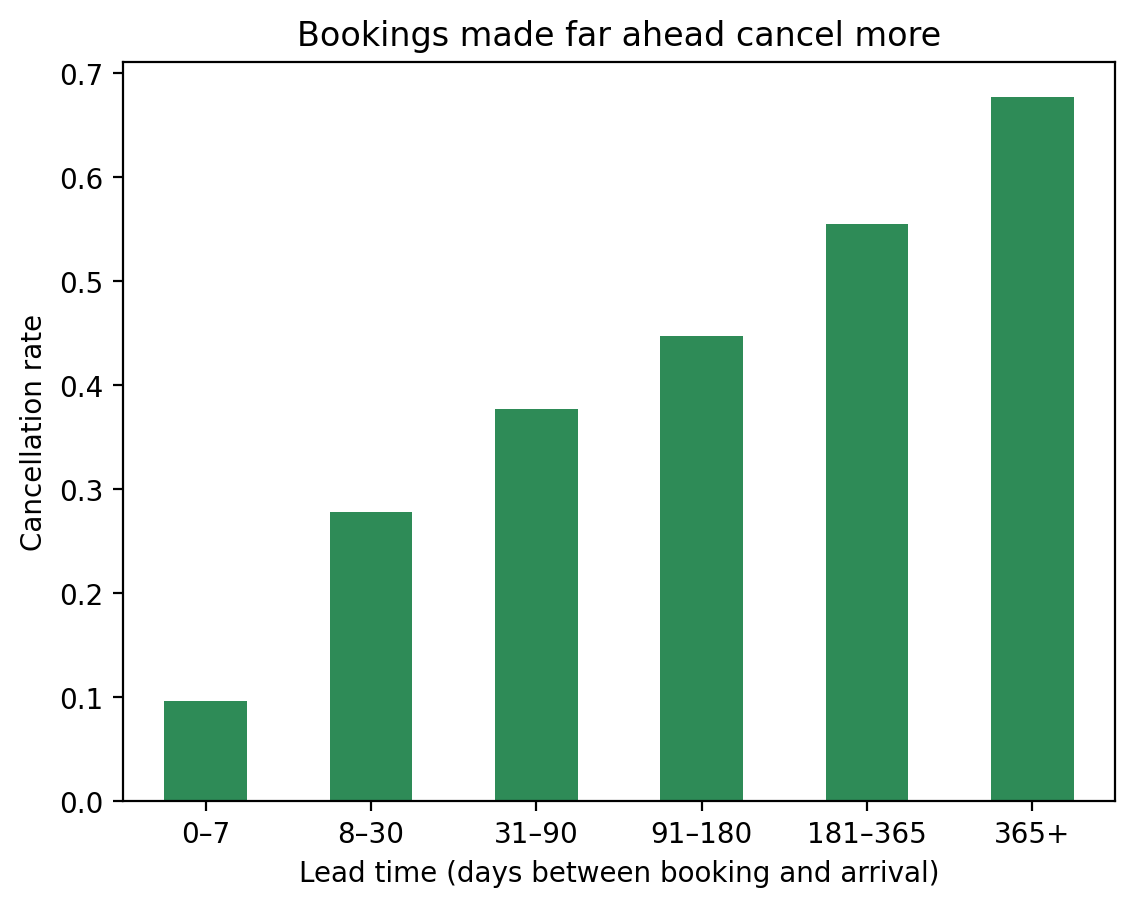

In [8]:
bins   = [-1, 7, 30, 90, 180, 365, df["lead_time"].max()]
labels = ["0–7", "8–30", "31–90", "91–180", "181–365", "365+"]
lead_group = pd.cut(df["lead_time"], bins=bins, labels=labels)

lead_rates = df.groupby(lead_group, observed=True)["is_canceled"].mean()
print(lead_rates.round(2))

lead_rates.plot(kind="bar", color="seagreen", rot=0)
plt.xlabel("Lead time (days between booking and arrival)")
plt.ylabel("Cancellation rate")
plt.title("Bookings made far ahead cancel more")
plt.show()

✏️ **Check a few more signals**

`df.groupby("COLUMN")["is_canceled"].mean()` splits the bookings by `COLUMN` and gives the cancellation rate for each group.

Write these four lines:
1. `print(df.groupby("hotel")["is_canceled"].mean())`
2. `print(df.groupby("total_of_special_requests")["is_canceled"].mean())`
3. `print(df.groupby("required_car_parking_spaces")["is_canceled"].mean())`
4. `print(df.groupby("deposit_type")["is_canceled"].mean())`

In [9]:
print(df.groupby("hotel")["is_canceled"].mean())
print(df.groupby("total_of_special_requests")["is_canceled"].mean())
print(df.groupby("required_car_parking_spaces")["is_canceled"].mean())
print(df.groupby("deposit_type")["is_canceled"].mean())

hotel
City Hotel      0.417270
Resort Hotel    0.277634
Name: is_canceled, dtype: float64
total_of_special_requests
0    0.477204
1    0.220249
2    0.220989
3    0.178614
4    0.105882
5    0.050000
Name: is_canceled, dtype: float64
required_car_parking_spaces
0    0.394949
1    0.000000
2    0.000000
3    0.000000
8    0.000000
Name: is_canceled, dtype: float64
deposit_type
No Deposit    0.283770
Non Refund    0.993624
Refundable    0.222222
Name: is_canceled, dtype: float64


✏️ Now make one of those into a bar chart. Add `.plot(kind="bar")` to the end:

`df.groupby("total_of_special_requests")["is_canceled"].mean().plot(kind="bar")`

then `plt.show()` on the next line.

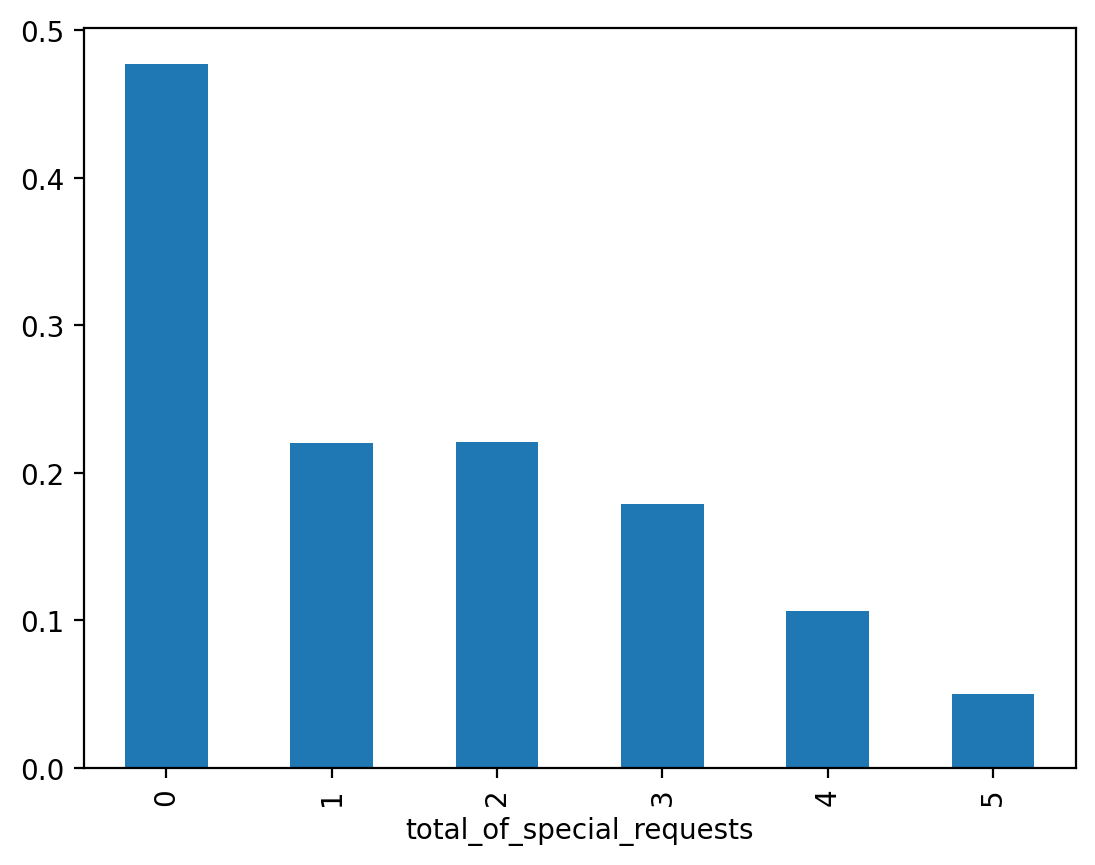

In [10]:
df.groupby("total_of_special_requests")["is_canceled"].mean().plot(kind="bar")
plt.show()

💬 **Discuss**
- Why might someone who asks for a parking spot or makes a special request be less likely to cancel?
- Look at `Non Refund`. **About 99% of non-refundable bookings were canceled.** That's backwards from what you'd expect: these guests paid up front and lose their money. Real pattern or, a data quirk?

*Your answer:*

### What's going on with `Non Refund`?

"Non Refund" means the deposit covers the **whole stay** and the guest doesn't get it back if they cancel. So why would 99% of them cancel? When a pattern looks backwards, look at **who** is in that group.

✏️ Write these lines:
1. `non_refund = df[df["deposit_type"] == "Non Refund"]` keeps only the non-refundable bookings
2. `print(non_refund["market_segment"].value_counts(normalize=True))`
3. `print(non_refund["total_of_special_requests"].value_counts(normalize=True))`
4. `print(non_refund["lead_time"].median(), df["lead_time"].median())` compares typical lead time to everyone else

In [ ]:
non_refund = df[df["deposit_type"] == "Non Refund"]
print(non_refund["market_segment"].value_counts(normalize=True))
print(non_refund["total_of_special_requests"].value_counts(normalize=True))
print(non_refund["lead_time"].median(), df["lead_time"].median())

✏️ Now check for **duplicate rows**: bookings that are an exact copy of another booking, in every column.

`.duplicated()` marks each row that's a copy of an earlier one as `True`, so its `.mean()` is the share of copies. Write:
1. `print(non_refund.duplicated().mean())`
2. `print(df.duplicated().mean())`

In [ ]:
print(non_refund.duplicated().mean())
print(df.duplicated().mean())

👀 **Observe**
- Almost all non-refundable bookings come from `Groups` or `Offline TA/TO` (travel agents and tour operators). Almost none are `Online TA` or `Direct`, which is how most individual guests book.
- 99.8% have **zero** special requests, and they're booked about **6 months** ahead (vs. about 2 months for everyone).
- **93%** of them are exact copies of another row, compared to 27% across the whole dataset.

**Our best guess:** these mostly aren't individual guests who paid up front. They look like **block bookings**: an agency reserves a batch of identical rooms months ahead for a group, then releases the rooms it can't fill. The "Non Refund" label probably reflects the agency's contract or how the hotel's system recorded the block, not a guest losing their money.

We can't prove this from the data alone. But it's a good reminder: a column's **name** tells you what it's supposed to mean, not what's actually going on in the data.

We'll keep `deposit_type` in. It's known when the booking is made, so it's not leakage. But watch what the tree does with it.

## 2. Clean: what do we drop?

Think about how the model would actually be used. A booking comes in, and the hotel wants to know **right then** whether it's likely to be canceled (so they can overbook a little, send a reminder, ask for a deposit, ...).

**Rule of thumb:** only use what you'd know **at the moment the booking is made**. If a column only exists because of the outcome, it's **leakage**: it makes the model look great in the notebook and useless in real life.

We'll also drop columns that **won't mean the same thing** for future bookings.

💬 Before scrolling down: go back to the column table in section 1. Which columns would the hotel **not** know when someone books?

*Your answer:*

Compare `reservation_status` to the target:

In [11]:
pd.crosstab(df["reservation_status"], df["is_canceled"])

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


👀 `Canceled` and `No-Show` are always `is_canceled = 1`, and `Check-Out` is always 0. This column **is** the answer. A tree would split on it once and get 100%, and we'd learn nothing.

### What we're dropping and why

| Column | Why we drop it |
|---|---|
| **Gives away the answer (leakage)** | |
| `reservation_status` | `Canceled` / `No-Show` = the target itself |
| `reservation_status_date` | Set after the booking is canceled or completed |
| `assigned_room_type` | Decided at check-in |
| `booking_changes` | Counted until check-in or cancellation |
| `days_in_waiting_list` | Counts days *after* the booking was made, so it isn't known when it comes in |
| `country` | Suspicious: bookings from Portugal cancel 57% of the time vs. 24% for everyone else. A guest's country is often only confirmed at check-in, so canceled bookings may keep a default value. |
| **Won't carry over to new bookings** | |
| `arrival_date_year` | Future bookings will be in years the tree has never seen, so a rule like "year ≤ 2016" is useless going forward |
| `agent`, `company` | ID numbers, not amounts, and `company` is missing for about 94% of rows |

✏️ **Drop the columns**

1. Make a list called `drop_cols` with the 9 column names from the table above, as strings. Start it like this:
   `drop_cols = ["reservation_status", "reservation_status_date", "assigned_room_type", ...]`
2. Write `df_model = df.drop(columns=drop_cols)` to make a new DataFrame without them. (We keep the original `df` untouched in case we want it later.)
3. Write `print(df_model.shape)`. You should get **(119390, 23)**: 32 columns minus the 9 we dropped. (The target is still in there; we separate it out in step 3.)

In [12]:
drop_cols = [
    "reservation_status", "reservation_status_date", "assigned_room_type",
    "booking_changes", "days_in_waiting_list", "country",
    "arrival_date_year", "agent", "company",
]
df_model = df.drop(columns=drop_cols)
print(df_model.shape)

(119390, 23)


### Missing values

✏️ Write `df_model.isna().sum()` to count the missing values in each column.

In [13]:
df_model.isna().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          4
babies                            0
meal                              0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
deposit_type                      0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests         0
dtype: int64

👀 Only `children` has missing values (4 rows). With 4 rows out of 119,390, the simplest fix is to assume that these 4 bookings had no children.

✏️ Write `df_model["children"] = df_model["children"].fillna(0)`, then check it worked with `print(df_model.isna().sum().sum())` (the total should be **0**).

In [14]:
df_model["children"] = df_model["children"].fillna(0)
print(df_model.isna().sum().sum())

0


## 3. Encode

scikit-learn trees only take numbers, so text columns like `hotel`, `meal`, and `deposit_type` need to become numbers. Just like in the linear regression workshop, we use **one-hot encoding** with `pd.get_dummies`: each category becomes its own 0/1 column, e.g. `deposit_type_Non Refund` is 1 for non-refundable bookings.

Two differences from linear regression:
- **No scaling needed.** A tree only ever asks "is `lead_time` ≤ 90?" Whether `lead_time` is in days or years doesn't change which bookings end up on which side.
- **No `drop_first`.** We keep every category, so the tree can ask about any one of them directly (like "is it non-refundable?").

✏️ **Make X and y**

Write these four lines:
1. `X = df_model.drop(columns="is_canceled")` gives the features (everything except the target)
2. `y = df_model["is_canceled"]` gives the target
3. `X = pd.get_dummies(X, dtype=int)` one-hot encodes every text column
4. `print(X.shape)`. You should have **63** columns now.

In [15]:
X = df_model.drop(columns="is_canceled")
y = df_model["is_canceled"]
X = pd.get_dummies(X, dtype=int)
print(X.shape)

(119390, 63)


Take a look at the new columns. Scroll right to find `deposit_type_Non Refund`.

In [16]:
X.head()

,lead_time,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,adr,required_car_parking_spaces,total_of_special_requests,hotel_City Hotel,hotel_Resort Hotel,arrival_date_month_April,arrival_date_month_August,arrival_date_month_December,arrival_date_month_February,arrival_date_month_January,arrival_date_month_July,arrival_date_month_June,arrival_date_month_March,arrival_date_month_May,arrival_date_month_November,arrival_date_month_October,arrival_date_month_September,meal_BB,meal_FB,meal_HB,meal_SC,meal_Undefined,market_segment_Aviation,market_segment_Complementary,market_segment_Corporate,market_segment_Direct,market_segment_Groups,market_segment_Offline TA/TO,market_segment_Online TA,market_segment_Undefined,distribution_channel_Corporate,distribution_channel_Direct,distribution_channel_GDS,distribution_channel_TA/TO,distribution_channel_Undefined,reserved_room_type_A,reserved_room_type_B,reserved_room_type_C,reserved_room_type_D,reserved_room_type_E,reserved_room_type_F,reserved_room_type_G,reserved_room_type_H,reserved_room_type_L,reserved_room_type_P,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Contract,customer_type_Group,customer_type_Transient,customer_type_Transient-Party
0,342,27,1,0,0,2,0.0,0,0,0,0,0.0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0
1,737,27,1,0,0,2,0.0,0,0,0,0,0.0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0
2,7,27,1,0,1,1,0.0,0,0,0,0,75.0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0
3,13,27,1,0,1,1,0.0,0,0,0,0,75.0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0
4,14,27,1,0,2,2,0.0,0,0,0,0,98.0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0


## 4. Split: 80% train / 20% test

We train on one part of the data and test on bookings the tree has **never seen**. That tells us how it would do on new bookings.

**Stratified** means both sets keep the same 37% / 63% mix of canceled vs. not. Without it, we could get unlucky and have a test set with a different cancellation rate.

👀 In our previous linear regression workshop we split **by date**, because we were predicting future sales. Here we split randomly. For a hotel actually using this model, splitting by date (train on older bookings, test on newer ones) would be more honest.

✏️ **Write it**
```python
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
```
- `test_size=0.2` puts 20% in the test set
- `stratify=y` keeps the canceled share the same in both
- `random_state=42` makes everyone's split identical, so our numbers match

Then print `len(X_train)` and `len(X_test)`. The test set should be **23,878** bookings.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(len(X_train), len(X_test))

95512 23878


✏️ Check the stratification worked: write `print(y_train.mean(), y_test.mean())`. Both should be about **0.37**.

In [18]:
print(y_train.mean(), y_test.mean())

0.37041418879303123 0.3704246586816316


## 5. Fit

### A tree small enough to read

Let's grow a tiny tree with only **2 questions in a row** so we can read every box.

✏️ Write these two lines:
1. `small_tree = DecisionTreeClassifier(max_depth=2, random_state=42)`
2. `small_tree.fit(X_train, y_train)`

In [19]:
small_tree = DecisionTreeClassifier(max_depth=2, random_state=42)
small_tree.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=2, random_state=42)

Now draw it.

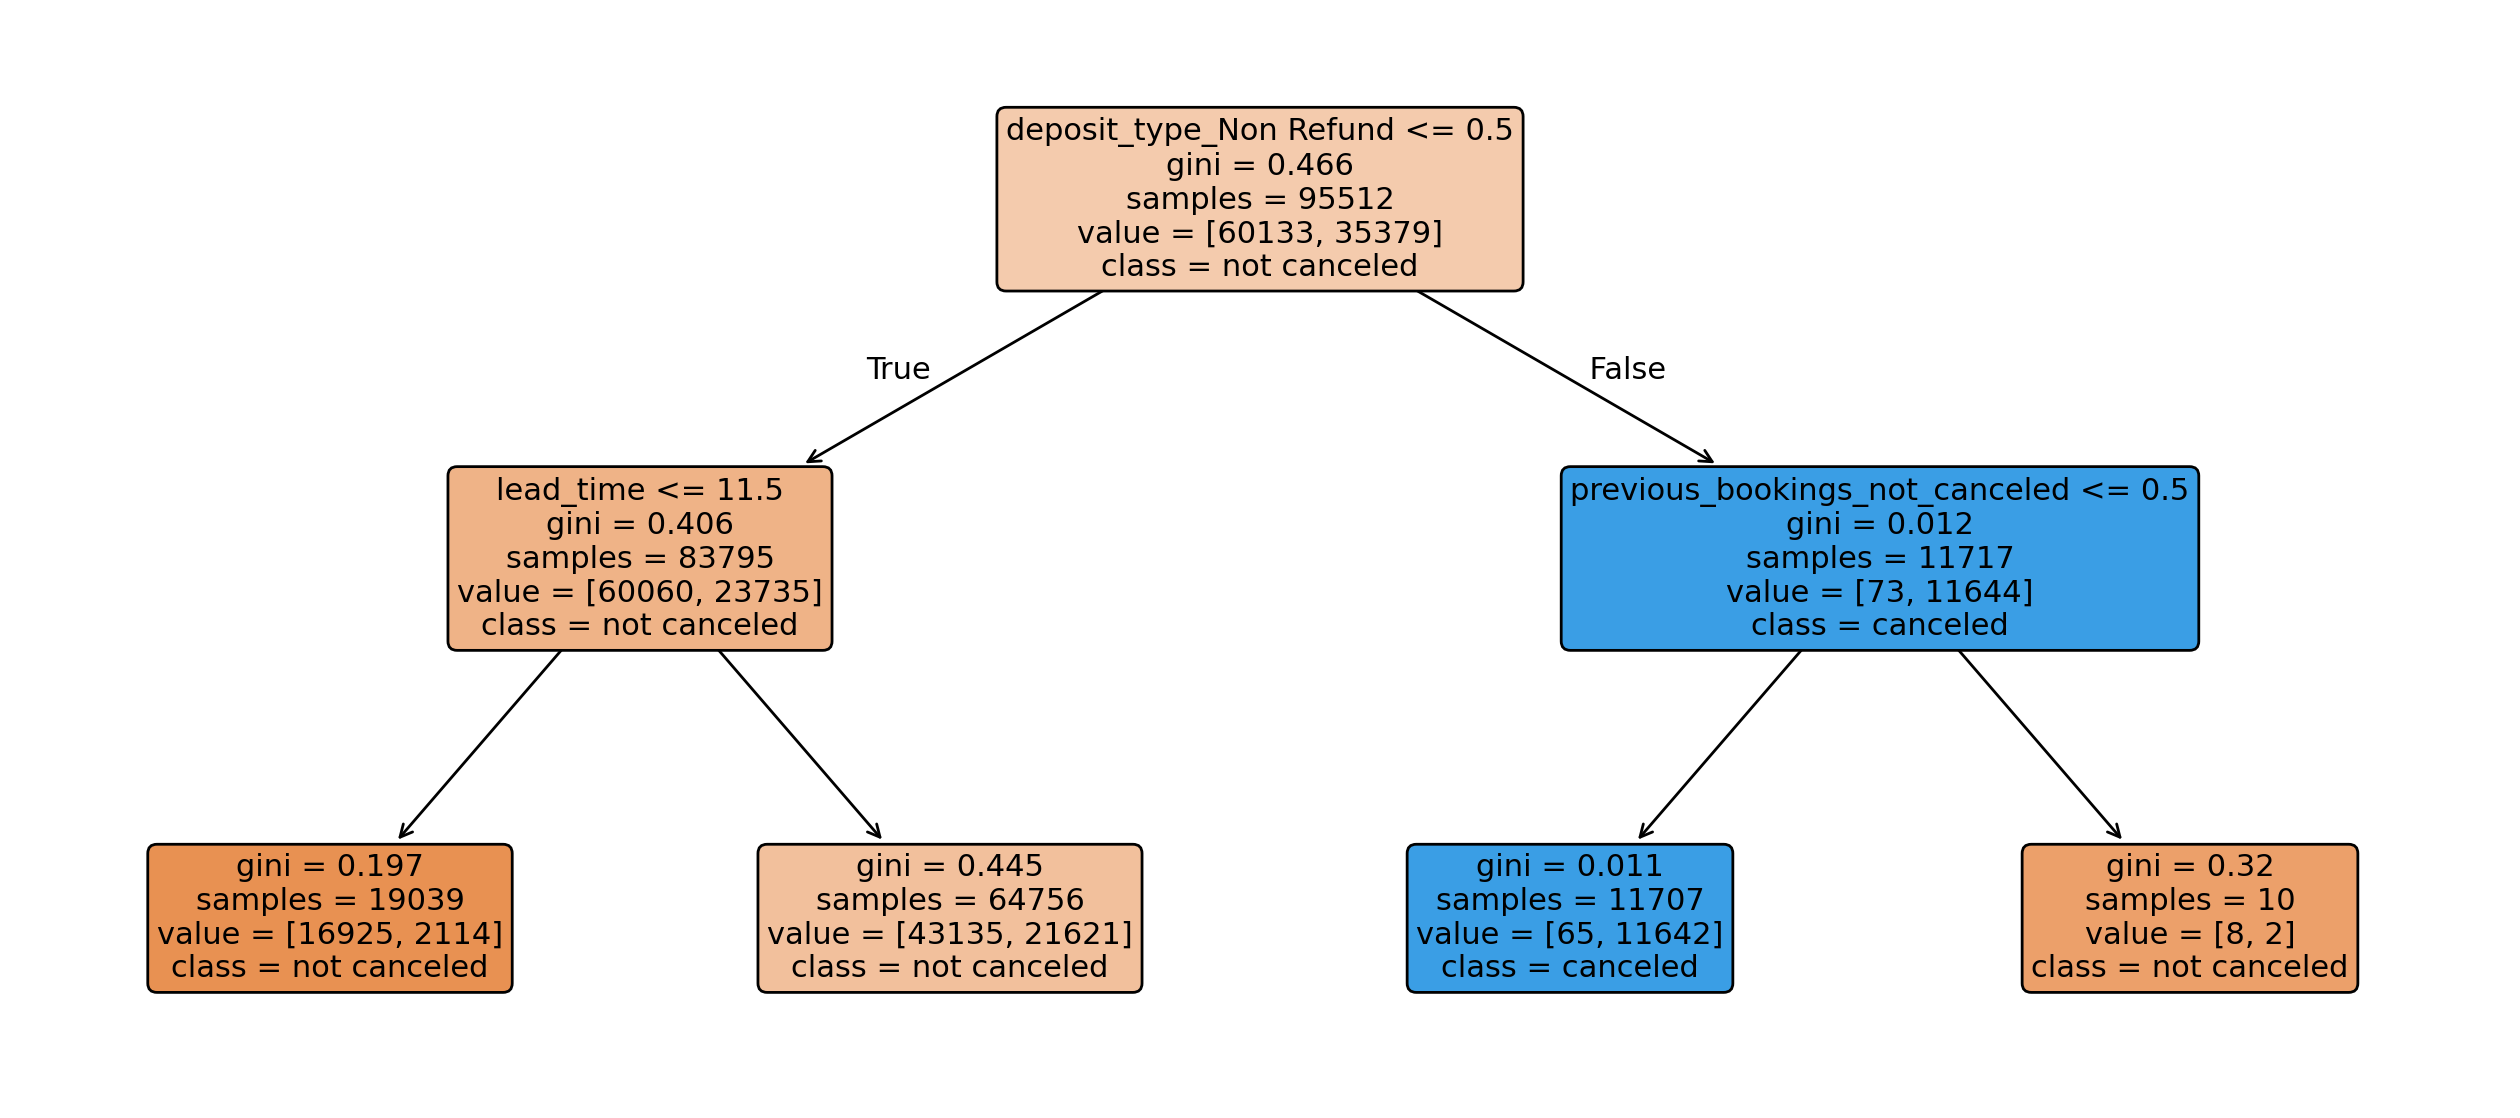

In [20]:
plt.figure(figsize=(16, 7))
plot_tree(
    small_tree,
    feature_names=X.columns,
    class_names=["not canceled", "canceled"],
    filled=True,
    rounded=True,
    fontsize=11,
)
plt.show()

**How to read each box**
- **First line:** the question. **Left = yes (True), right = no (False).**
  - For a one-hot column, `deposit_type_Non Refund <= 0.5` means "is this column 0?", which is the same as asking "is it **not** non-refundable?"
- **`gini`:** impurity of that group. 0 = everyone has the same answer, 0.5 = a 50/50 coin flip.
- **`samples`:** how many training bookings landed here.
- **`value`:** how the bookings in this box split between [not canceled, canceled]. (Depending on your scikit-learn version, these show as counts or as fractions.)
- **`class`:** the majority vote. That's the prediction for any booking that ends up in this box.

The top box is the **root**, the middle ones are **nodes**, and the bottom ones are **leaves**.

💬 **Discuss**
- What did the tree pick as its **first** question? Nobody told it to ask that. Does it match what we saw in the quick charts?
- Look at the two leaves on the **left**. They both predict "not canceled". So why did the tree bother splitting? (Hint: compare how mixed they are. A leaf where 11% cancel and a leaf where 33% cancel give the same vote, but very different confidence.)

*Your answer:*

### How good is the small tree?

The simplest score for classification is **accuracy**: the share of test bookings the tree got right.

✏️ Write these lines:
1. `y_pred_small = small_tree.predict(X_test)` gives a prediction for every test booking
2. `print(accuracy_score(y_test, y_pred_small))`
3. `baseline_acc = (y_test == 0).mean()` is the accuracy of always guessing "not canceled"
4. `print(baseline_acc)`

In [23]:
y_pred_small = small_tree.predict(X_test)
print(accuracy_score(y_test, y_pred_small))

baseline_acc = (y_test == 0).mean()
print(baseline_acc)

0.748178239383533
0.6295753413183683


👀 Two questions already take us from ~63% to ~75%. But is a deeper tree always better?

### How deep should the tree go? (loop over `max_depth`)

`max_depth` is how many questions in a row the tree can ask, at most.
- **Too shallow:** simple rules, misses patterns (**underfit**)
- **Too deep:** a leaf for almost every booking, memorizes noise (**overfit**)

Instead of guessing, we'll **try a bunch of depths** and record how each one does on the training set and on the test set.

✏️ **Write the loop.** Follow these steps in one cell:

1. Make the list of depths to try:
   `depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, None]`
   (`None` means no limit: the tree keeps splitting until every leaf is pure)
2. Make two empty lists to hold the results:
   `train_scores = []`
   `test_scores = []`
3. Start the loop: `for d in depths:`
4. **Inside the loop** (indented), make and fit a tree with that depth:
   `tree = DecisionTreeClassifier(max_depth=d, random_state=42)`
   `tree.fit(X_train, y_train)`
5. Still inside the loop, save the accuracy on each set. (`.score()` gives accuracy directly.)
   `train_scores.append(tree.score(X_train, y_train))`
   `test_scores.append(tree.score(X_test, y_test))`
6. Still inside the loop, print the depth and both scores:
   `print(d, round(train_scores[-1], 3), round(test_scores[-1], 3))`
   (`[-1]` means "the last item in the list", i.e. the one we just added)

In [24]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, None]
train_scores = []
test_scores = []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    tree.fit(X_train, y_train)
    train_scores.append(tree.score(X_train, y_train))
    test_scores.append(tree.score(X_test, y_test))
    print(d, round(train_scores[-1], 3), round(test_scores[-1], 3))

1 0.751 0.748
2 0.751 0.748
3 0.767 0.765
4 0.768 0.766
5 0.804 0.803
6 0.809 0.809
8 0.816 0.814
10 0.822 0.817
12 0.83 0.821
15 0.851 0.823
20 0.903 0.825
25 0.954 0.819
None 0.991 0.817


✏️ **Graph it**

We'll plot depth on the x-axis and accuracy on the y-axis, with one line for train and one for test.

1. Turn the depths into text labels, so `None` can go on the axis and the points are evenly spaced:
   `labels = [str(d) for d in depths]`
2. `plt.figure(figsize=(9, 5))`
3. `plt.plot(labels, train_scores, marker="o", label="Train accuracy")`
4. `plt.plot(labels, test_scores, marker="o", label="Test accuracy")`
5. Add the baseline as a flat dashed line:
   `plt.axhline(baseline_acc, color="gray", linestyle="--", label="Baseline (always 'not canceled')")`
6. Labels and legend:
   `plt.xlabel("max_depth")`
   `plt.ylabel("Accuracy")`
   `plt.title("Deeper isn't always better")`
   `plt.legend()`
7. `plt.show()`

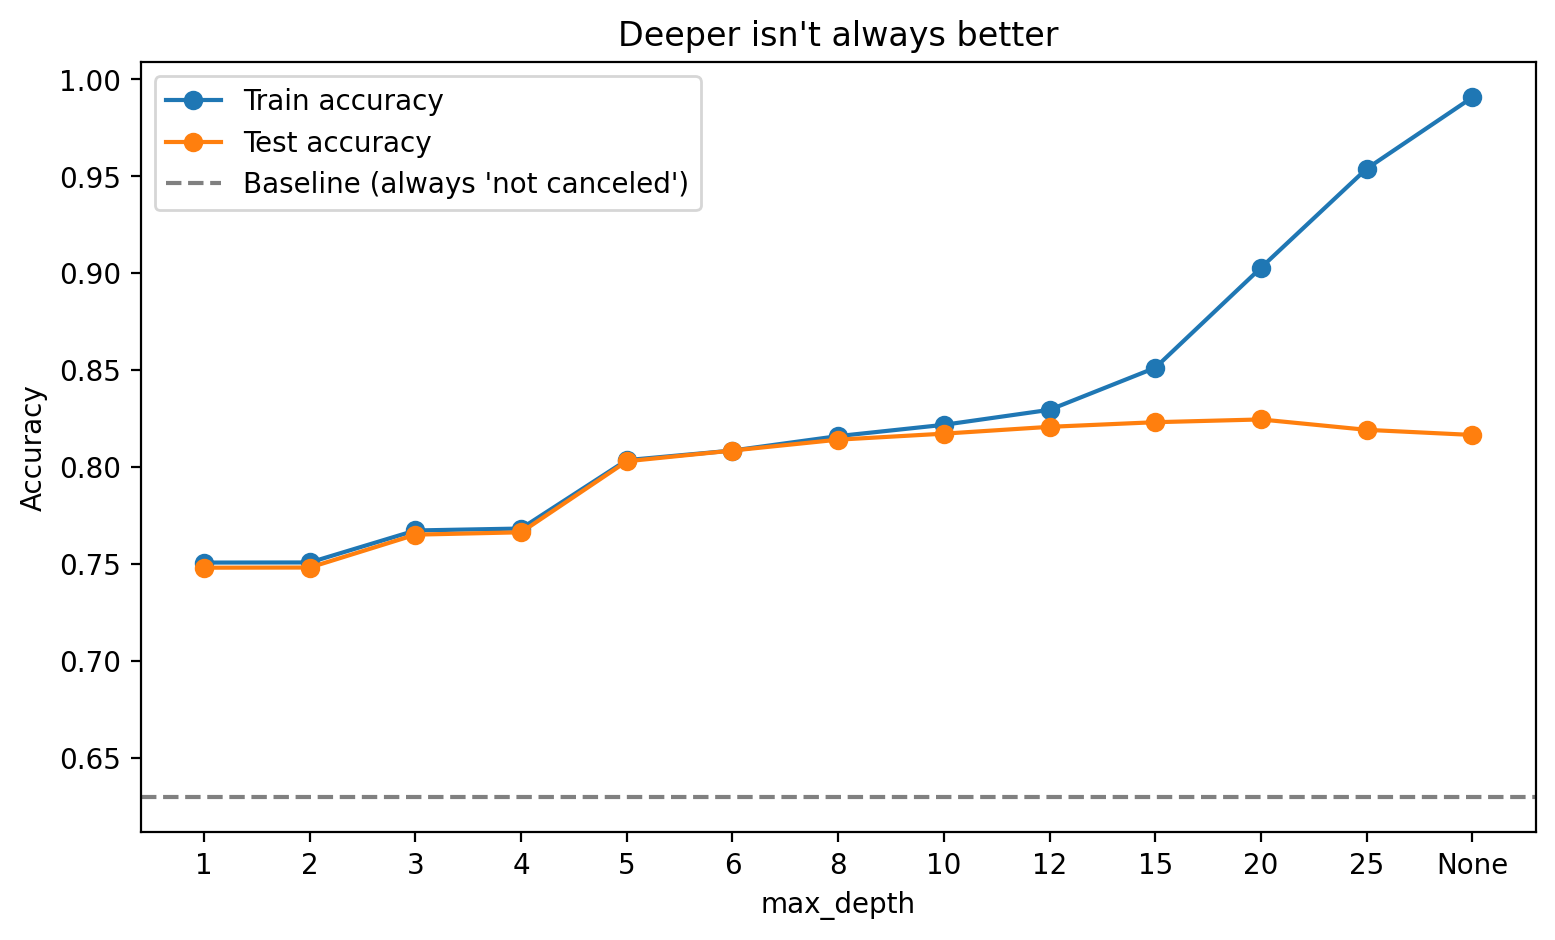

In [25]:
labels = [str(d) for d in depths]

plt.figure(figsize=(9, 5))
plt.plot(labels, train_scores, marker="o", label="Train accuracy")
plt.plot(labels, test_scores, marker="o", label="Test accuracy")
plt.axhline(baseline_acc, color="gray", linestyle="--", label="Baseline (always 'not canceled')")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Deeper isn't always better")
plt.legend()
plt.show()

After the loop finishes, `tree` is the **last** tree it built: the one with no depth limit.

✏️ Write `print(tree.get_depth())` to see how deep it grew on its own.

In [26]:
print(tree.get_depth())

43


💬 **Discuss**
- At small depths, the train and test lines sit on top of each other. Where do they start to **pull apart**? What does that gap mean?
- The unlimited tree gets about **99% on train** but only about **82% on test**. What did it learn that doesn't carry over to new bookings?
- Which depth has the best test accuracy? Is it worth having a much bigger tree for a fraction of a percent?

*Your answer:*

👀 **Observe**
- When train accuracy keeps climbing but test accuracy doesn't, the extra splits are **memorizing** the training bookings, not learning anything new. That's **overfitting**.
- Test accuracy is basically flat after depth 8 while the tree gets a lot bigger. We'll go with **depth 8**: almost as accurate as the best, and much smaller and easier to trust.
- One catch: we picked the depth by looking at the **test** set, so the test set isn't completely "unseen" anymore. The proper fix is a separate validation set or cross-validation. That's a challenge at the end.

## 6. Evaluate the depth-8 tree

✏️ Write these three lines:
1. `final_tree = DecisionTreeClassifier(max_depth=8, random_state=42)`
2. `final_tree.fit(X_train, y_train)`
3. `y_pred = final_tree.predict(X_test)`

In [28]:
final_tree = DecisionTreeClassifier(max_depth=8, random_state=42)
final_tree.fit(X_train, y_train)
y_pred = final_tree.predict(X_test)

### What kinds of mistakes?

Accuracy is one number, but there are **two different ways** to be wrong, and they cost the hotel different things. A **confusion matrix** counts each kind:

| | Predicted: not canceled | Predicted: canceled |
|---|---|---|
| **Actually not canceled** | ✅ correct | ❌ **false alarm**: we flagged a guest who showed up |
| **Actually canceled** | ❌ **missed it**: the room sits empty | ✅ correct |

From those four counts we get:

| Metric | Question it answers | Good is... |
|---|---|---|
| **Accuracy** | Out of all bookings, what share did we get right? | Higher |
| **Precision** | When the tree says "canceled", how often is it right? | Higher |
| **Recall** | Out of all the bookings that **really** canceled, what share did we catch? | Higher |

⚠️ Like before, we always compute these on the **test** set.

✏️ **Confusion matrix**

Write `print(confusion_matrix(y_test, y_pred))`. The rows are the actual answer (0, then 1) and the columns are the prediction (0, then 1), same layout as the table above.

In [29]:
print(confusion_matrix(y_test, y_pred))

[[13907  1126]
 [ 3312  5533]]


Here's the same thing as a picture:

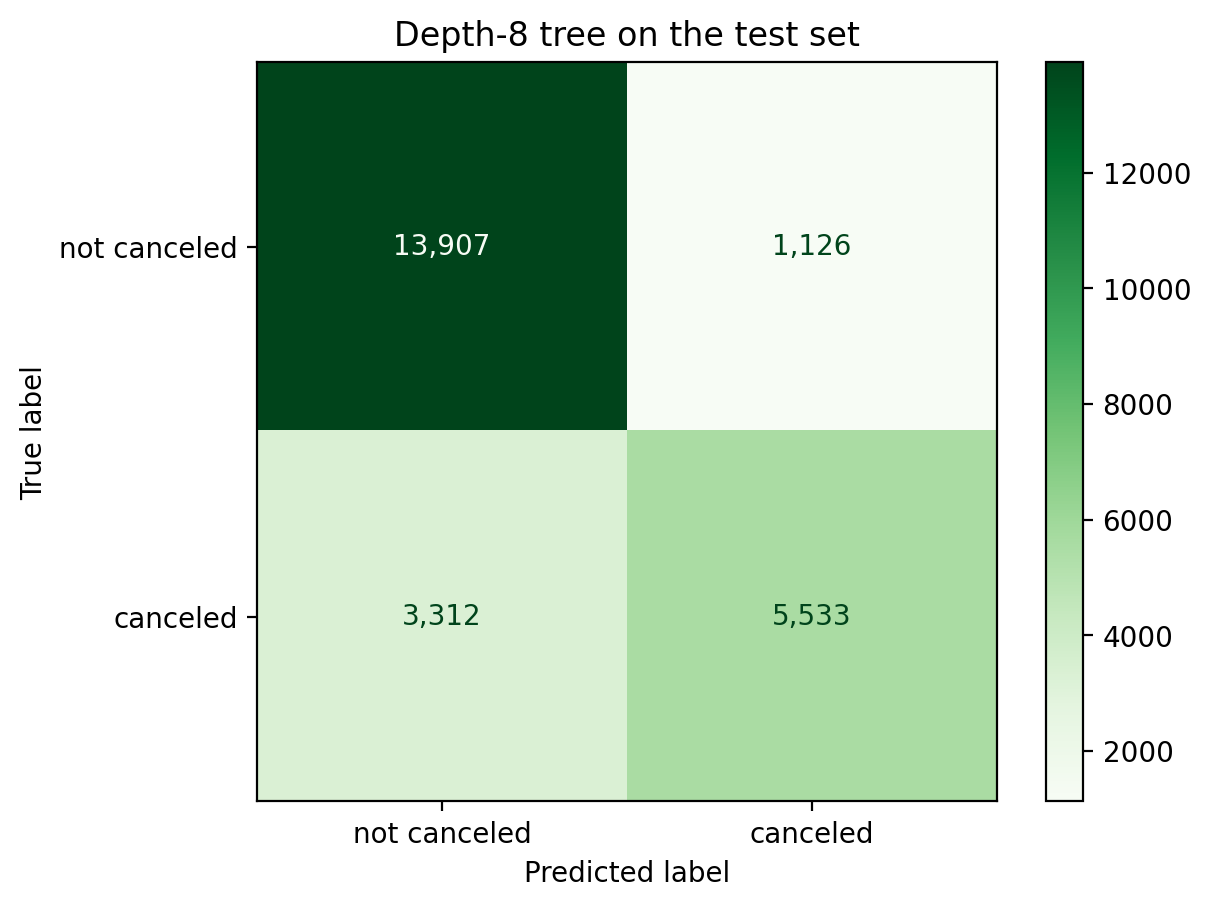

In [30]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["not canceled", "canceled"],
    cmap="Greens",
    values_format=",",
)
plt.title("Depth-8 tree on the test set")
plt.show()

✏️ **Accuracy, precision, recall**

Write these three lines. (`:.1%` prints a fraction as a percentage with 1 decimal.)
1. `print(f"Accuracy:  {accuracy_score(y_test, y_pred):.1%}")`
2. `print(f"Precision: {precision_score(y_test, y_pred):.1%}")`
3. `print(f"Recall:    {recall_score(y_test, y_pred):.1%}")`

You should get about **81%, 83%, 63%**.

In [31]:
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.1%}")
print(f"Precision: {precision_score(y_test, y_pred):.1%}")
print(f"Recall:    {recall_score(y_test, y_pred):.1%}")

Accuracy:  81.4%
Precision: 83.1%
Recall:    62.6%


💬 **Discuss**
- Say it in words: "The tree catches __% of real cancellations, and when it flags one, it's right __% of the time."
- Which mistake is worse for the hotel? A **missed** cancellation (an empty room they could have resold) or a **false alarm** (they overbook, the guest shows up, and there's no room)?
- If the hotel cared most about catching cancellations, would they want higher precision or higher recall?

*Your answer:*

### What does the tree lean on?

`feature_importances_` tells us how much each feature helped. Every split lowers the Gini impurity a bit, and each feature gets credit for the splits it was used in. The importances add up to 1 (100%).

✏️ Write these two lines:
1. `importances = pd.Series(final_tree.feature_importances_, index=X.columns).sort_values(ascending=False)`
2. `importances.head(10)`

In [32]:
importances = pd.Series(final_tree.feature_importances_, index=X.columns).sort_values(ascending=False)
importances.head(10)

deposit_type_Non Refund           0.536037
total_of_special_requests         0.108242
lead_time                         0.094048
market_segment_Online TA          0.086588
previous_cancellations            0.073395
required_car_parking_spaces       0.042822
customer_type_Transient           0.026339
previous_bookings_not_canceled    0.011043
arrival_date_week_number          0.003944
customer_type_Transient-Party     0.003683
dtype: float64

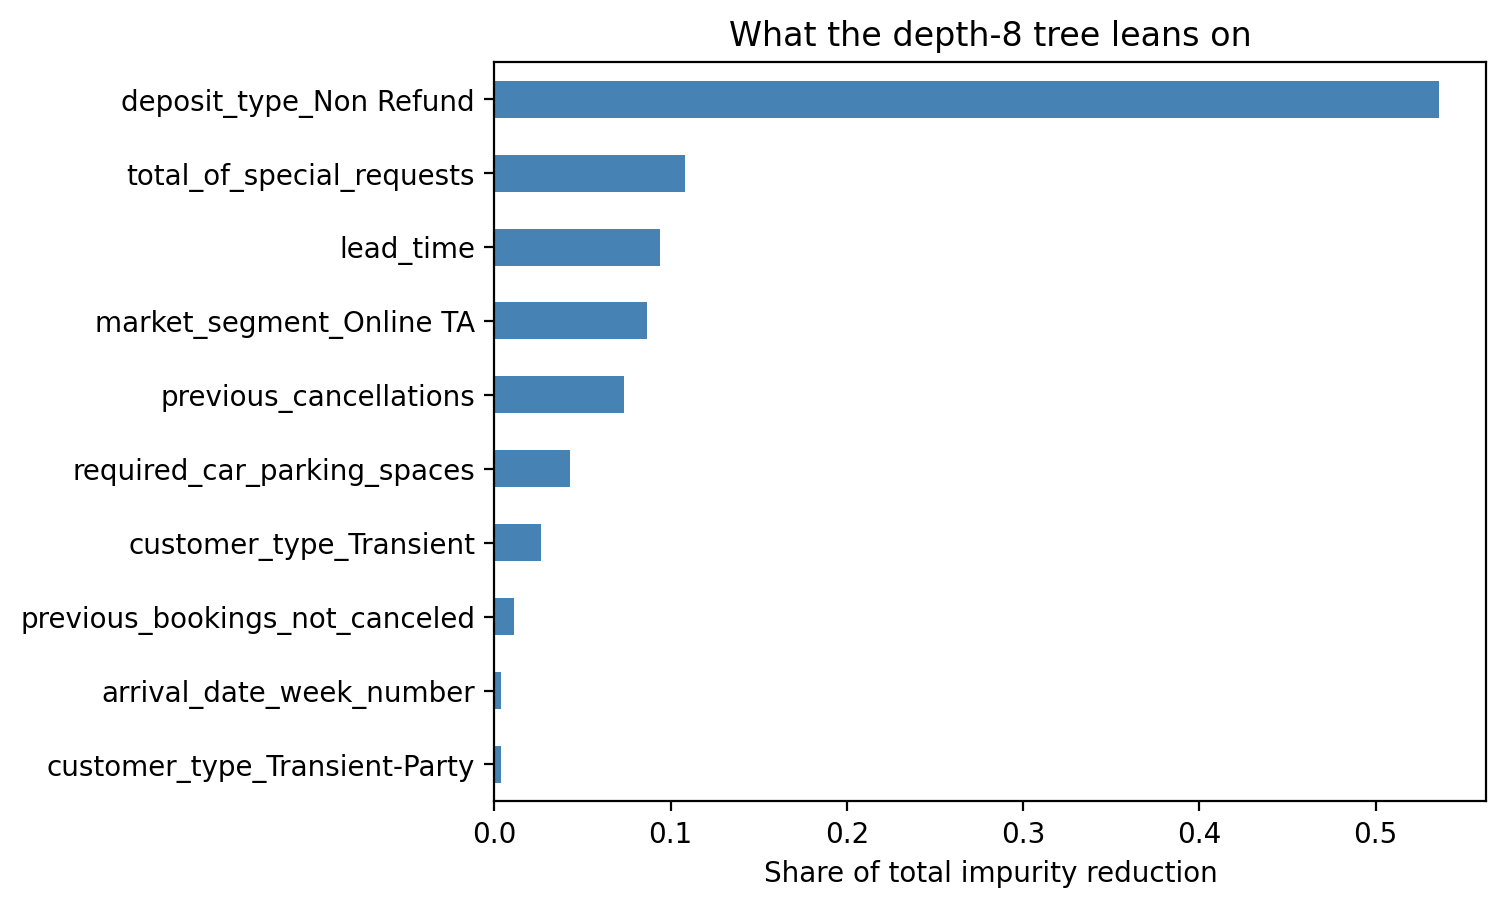

In [33]:
importances.head(10).sort_values().plot(kind="barh", color="steelblue")
plt.xlabel("Share of total impurity reduction")
plt.title("What the depth-8 tree leans on")
plt.show()

💬 **Discuss**
- More than half of the tree's "work" comes from **one** column: `deposit_type_Non Refund`. Think back to what those bookings looked like. Is the tree learning **who cancels**, or learning to **spot agency block bookings**? What happens when a hotel with different booking contracts uses this model?
- Compare the top features to the quick charts (lead time, special requests, parking). Did exploring the data predict what the tree would pick?
- `hotel` doesn't show up near the top, even though City Hotel cancels a lot more. Why might that be? (Hint: the tree can only use so many questions, and other columns might already carry the same information.)

*Your answer:*

👀 **Observe: the duplicates make the tree look better than it is**

Remember that 93% of the non-refundable bookings are copies of another row. When we split randomly, copies of the same block booking land in **both** train and test. So for a lot of test rows, the tree has effectively already seen the answer. That's a quiet form of leakage.

So the 81% is probably **optimistic**. Two challenges below test how much: removing the duplicates, and splitting by time.

## 7. Wrap-up

**Takeaways**
1. **A tree is a list of yes/no questions.** At each step, it tries every possible question and keeps the one that makes the groups least mixed (lowest Gini). Nobody writes the rules; the data picks them.
2. **Always do descriptive stats first.** `describe()` and a few groupbys showed us the missing values, the weird prices, the baseline, and the features that matter.
3. **Drop what you wouldn't know at booking time.** If a column only exists because of the outcome, it's leakage.
4. **Depth controls the fit.** Too shallow underfits, too deep memorizes. Watch the gap between train and test accuracy.
5. **Always compare to a baseline.** 81% sounds great, but the bar was already 63%.
6. **Accuracy isn't the whole story.** The confusion matrix shows *which* mistakes the model makes.

### Challenges
- **Loop over a different setting.** Copy your depth loop, but keep `max_depth=None` and loop over `min_samples_leaf` in `[1, 5, 20, 50, 100, 200, 500]` instead. Graph it the same way. Does it fix overfitting too?
- **Put `country` back in.** Re-run with `country` (fill its missing values with `"Unknown"` first). Does test accuracy jump? Does that make you *more* or *less* suspicious of it?
- **Remove the duplicates.** Right after loading, add `df = df.drop_duplicates()` and rerun everything. Check the new baseline first (it changes!), then compare: how far above the baseline is the tree now? How important is `deposit_type_Non Refund`?
- **Split by time.** Train on bookings arriving before 2017 and test on 2017 arrivals (you'll need `arrival_date_year` to make the split, then drop it from X). How does accuracy compare to the random split?
- **Pick the depth without peeking.** Split `X_train` again into a smaller train set and a **validation** set, choose `max_depth` on the validation set, and only touch the test set once at the end.
- **Random forest.** Try `RandomForestClassifier(n_estimators=100, random_state=42)` from `sklearn.ensemble`. How much better is it than one tree? What do you lose?